# 🐧 Palmer Penguins ile Çoklu Sınıflandırma (Multi-Class Classification)
**PyTorch Derin Öğrenme Eğitimi - Kapsamlı Uygulama Ödevi**

Bu çalışmada, Antarktika'daki Palmer Takımadaları'nda yaşayan **3 farklı penguen türünü (*Adelie, Chinstrap, Gentoo*)** morfolojik ölçümlerine (gaga, yüzgeç ve vücut ağırlığı) göre sınıflandıran derin yapay sinir ağı mimarisi inşa edilmiştir.

### 📋 Proje İş Akışı:
1. **Keşifsel Veri Analizi (EDA) & Eksik Veri Temizliği:** Veri setinin incelenmesi ve `NaN` yönetimi.
2. **Özellik & Hedef Ayrımı:** Sınıf etiketlerinin `LabelEncoder` ile sayıya çevrilmesi.
3. **Train / Test Ayrımı (`stratify=y`):** Sınıf oranlarının dengeli korunması.
4. **Vaka İncelemesi (Feature Scaling):** Farklı ölçeklerdeki özelliklerin (`body_mass_g` vs `bill_depth_mm`) modele etkisi ve `StandardScaler` çözümü.
5. **PyTorch Tenzör Dönüşümü:** `float32` ve `long` (int64) veri tipi standartları.
6. **Yapay Sinir Ağı Mimarisi (`nn.Module`):** Parametrik çok katmanlı algılayıcı (MLP).
7. **Eğitim Döngüsü (Training Loop):** `CrossEntropyLoss` ve `Adam` ile modelin eğitilmesi.
8. **Performans Analizi & Confusion Matrix:** Sınıflandırma başarısının değerlendirilmesi.
9. **Model Kaydı (`.pth`) & Canlı Çıkarım (Inference):** Modelin diske kaydedilip yeni veriyle test edilmesi.

## 1. Gerekli Kütüphanelerin Yüklenmesi

In [1]:
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Grafikler için modern görsel stil
sns.set_theme(style="whitegrid")
print(f"PyTorch Versiyonu: {torch.__version__}")

PyTorch Versiyonu: 2.14.0


## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

In [2]:
df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
# Veri setinin genel yapısı ve tipleri
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


In [4]:
# Sayısal özelliklerin istatistiksel özeti
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


In [5]:
# Hedef sınıf (species) dağılımı
df["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

### 📊 Veri Dağılımının Görselleştirilmesi
Gaga uzunluğu (`bill_length_mm`) ve yüzgeç uzunluğu (`flipper_length_mm`) arasındaki ilişkiye göre türlerin dağılımına bakalım:

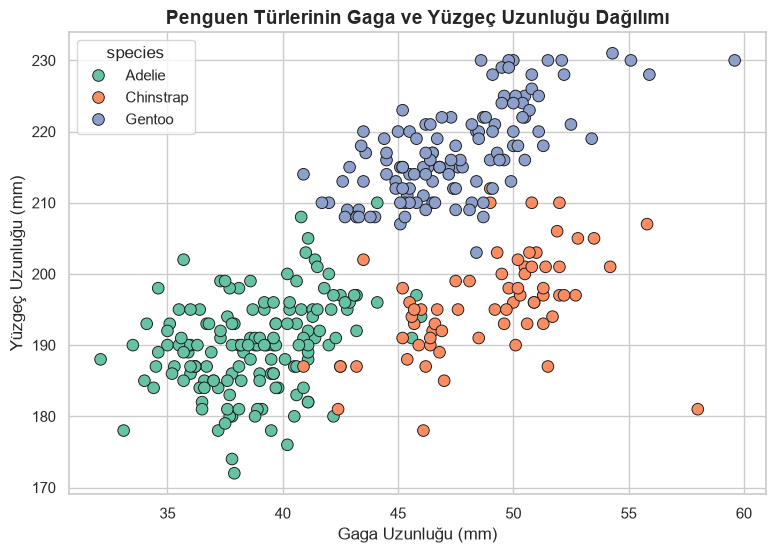

In [6]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",
    palette="Set2",
    s=70,
    edgecolor="k"
)
plt.title("Penguen Türlerinin Gaga ve Yüzgeç Uzunluğu Dağılımı", fontsize=14, weight="bold")
plt.xlabel("Gaga Uzunluğu (mm)")
plt.ylabel("Yüzgeç Uzunluğu (mm)")
plt.show()

## 3. Eksik Veri Analizi ve Temizlik

Gerçek hayat veri setlerinde eksik (`NaN`) değerler bulunur. Eksik veri miktarını tespit edip uygun stratejiyi belirleyelim.

In [7]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

> [!NOTE]
> **Eksik Veri Kararı:** 
> Toplam 344 satırlık veride ölçüm değerlerinde sadece 2 satır, cinsiyette ise 11 satır eksiktir. Verinin %96.8'i eksiksiz olduğu için bu 11 satırı `dropna()` ile silmek veri setinin genel yapısını bozmaz ve en güvenli çözümdür.

In [8]:
# Eksik satırları temizliyoruz
df = df.dropna()
print(f"Temizlik sonrası veri şekli: {df.shape}")
print(f"Kalan eksik veri sayısı:\n{df.isnull().sum().to_dict()}")

Temizlik sonrası veri şekli: (333, 7)
Kalan eksik veri sayısı:
{'species': 0, 'island': 0, 'bill_length_mm': 0, 'bill_depth_mm': 0, 'flipper_length_mm': 0, 'body_mass_g': 0, 'sex': 0}


## 4. Özellik ($X$) - Hedef ($y$) Ayrımı & Label Encoding

* **Hedef ($y$):** `species` (Adelie, Chinstrap, Gentoo). Metin formatında olduğu için `LabelEncoder` ile `[0, 1, 2]` tam sayılarına dönüştürülmelidir.
* **Girdiler ($X$):** 4 morfolojik ölçüm (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`).

In [9]:
# Hedef etiketi (y) sayısallaştırma
le = LabelEncoder()
y = le.fit_transform(df["species"])

print("Sınıf İsimleri (Classes):", le.classes_)
for i, c in enumerate(le.classes_):
    print(f"  {i} -> {c}")

Sınıf İsimleri (Classes): ['Adelie' 'Chinstrap' 'Gentoo']
  0 -> Adelie
  1 -> Chinstrap
  2 -> Gentoo


In [10]:
# Girdi matrisini (X) oluşturma (4 sayısal özellik)
X = df[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].values
print(f"X Boyutu: {X.shape} | y Boyutu: {y.shape}")

X Boyutu: (333, 4) | y Boyutu: (333,)


## 5. Train / Test Ayrımı (`stratify=y`)

Veriyi %80 Eğitim (Train) ve %20 Test olarak ayırıyoruz. 
`stratify=y` parametresi sayesinde her penguen türü eğitim ve test kümelerine orijinal verideki oranlarıyla dağıtılır.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Eğitim Verisi : X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Test Verisi   : X_test:  {X_test.shape},  y_test:  {y_test.shape}")

Eğitim Verisi : X_train: (266, 4), y_train: (266,)
Test Verisi   : X_test:  (67, 4),  y_test:  (67,)


## 6. Vaka İncelemesi: Neden `StandardScaler` (Ölçeklendirme) Kullandık?

> [!WARNING]
> **Ölçek Uçurumu Problemi:**
> Özelliklerimize baktığımızda gaga derinliği ortalama **17 mm** iken, vücut kütlesi (`body_mass_g`) **4500 gram** seviyelerindedir!
> Yapay sinir ağları büyük sayılara sahip özelliklerin ağırlıklarını kontrolsüzce büyüterek gradyanların patlamasına veya küçük özelliklerin ezilmesine neden olur. Ölçeklendirme yapılmadığında model **%43 doğrulukta sıkışıp kalmaktadır.**
>
> **Çözüm:** `StandardScaler` uygulayarak tüm özellikleri $\mu = 0$ (ortalama) ve $\sigma = 1$ (standart sapma) teraziye çekiyoruz.

In [12]:
# Sadece X_train üzerinde fit edilir, X_test sadece transform edilir (Data Leakage önleme!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Ölçeklendirme Öncesi İlk Örnek:\n", X_train[0])
print("\nÖlçeklendirme Sonrası İlk Örnek (Standardize):\n", X_train_scaled[0])

Ölçeklendirme Öncesi İlk Örnek:
 [  44.9   13.3  213.  5100. ]

Ölçeklendirme Sonrası İlk Örnek (Standardize):
 [ 0.16732502 -1.99231135  0.83478089  1.08239437]


### 🔢 PyTorch Tenzörlerine Dönüştürme (Kritik Kurallar)
1. **$X$ (Girdiler):** `torch.float32` tipinde ve 2 boyutlu `(N, 4)` olmalıdır.
2. **$y$ (Etiketler):** `nn.CrossEntropyLoss` sınıf indekslerini beklediği için `torch.long` (int64) tipinde ve 1 boyutlu `(N,)` kalmalıdır (`unsqueeze` yapılmaz!).

In [13]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print(f"X_train Tipi: {X_train_tensor.dtype}, Boyutu: {X_train_tensor.shape}")
print(f"y_train Tipi: {y_train_tensor.dtype}, Boyutu: {y_train_tensor.shape}")

X_train Tipi: torch.float32, Boyutu: torch.Size([266, 4])
y_train Tipi: torch.int64, Boyutu: torch.Size([266])


## 7. Parametrik Model Mimarisi (`nn.Module`)

Esnek ve modüler bir mimari için katman boyutlarını parametrik (`in_features`, `out_features`, `hidden_units`) olarak tanımlıyoruz:

In [14]:
class PenguinClassifier(nn.Module):
    """
    Penguen Türü Sınıflandırma Yapay Sinir Ağı Mimarisi (MLP)
    """
    def __init__(self, in_features: int = 4, out_features: int = 3, hidden_units: int = 16):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Linear(in_features=in_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=out_features)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layer_stack(x)

# Modelin başlatılması
torch.manual_seed(42)
model = PenguinClassifier(in_features=4, out_features=3, hidden_units=16)
print(model)

PenguinClassifier(
  (layer_stack): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


## 8. Kayıp Fonksiyonu, Optimizer ve Metrik Tanımı

In [15]:
# Kayıp Fonksiyonu: Ham lojitleri alır, Softmax'ı içeride kararlı uygular
loss_fn = nn.CrossEntropyLoss()

# Optimizer: Ağırlıkları güncelleyen Adam algoritması
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

# Doğruluk (Accuracy) metriği
def calculate_accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

## 9. Model Eğitimi (Training Loop - 100 Epoch)

In [16]:
torch.manual_seed(42)
epochs = 100

# Metrikleri kaydetmek için listeler
epoch_count = []
train_loss_values = []
test_loss_values = []
train_acc_values = []
test_acc_values = []

for epoch in range(epochs):
    ### --- 1. EĞİTİM (TRAINING) ---
    model.train()
    
    # 1. Forward Pass (Ham lojitler)
    y_logits = model(X_train_tensor)
    y_pred = y_logits.argmax(dim=1)
    
    # 2. Loss & Accuracy
    loss = loss_fn(y_logits, y_train_tensor)
    acc = calculate_accuracy(y_train_tensor, y_pred)
    
    # 3. Gradyan Sıfırlama
    optimizer.zero_grad()
    
    # 4. Backpropagation (Geriye Yayılım)
    loss.backward()
    
    # 5. Gradient Descent (Ağırlık Güncelleme)
    optimizer.step()
    
    ### --- 2. DEĞERLENDİRME (TESTING) ---
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test_tensor)
        test_pred = test_logits.argmax(dim=1)
        
        test_loss = loss_fn(test_logits, y_test_tensor)
        test_acc = calculate_accuracy(y_test_tensor, test_pred)
        
    # Her epoch kaydet
    epoch_count.append(epoch)
    train_loss_values.append(loss.item())
    test_loss_values.append(test_loss.item())
    train_acc_values.append(acc)
    test_acc_values.append(test_acc)
    
    # Her 10 epoch'ta bir ekrana yazdır
    if epoch % 10 == 0:
        print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f}, Train Acc: %{acc:.2f} | Test Loss: {test_loss:.4f}, Test Acc: %{test_acc:.2f}")

print(f"\nEğitim Tamamlandı! Nihai Test Başarısı: %{test_acc_values[-1]:.2f}")

Epoch:   0 | Train Loss: 1.1255, Train Acc: %20.30 | Test Loss: 1.0835, Test Acc: %25.37
Epoch:  10 | Train Loss: 0.6674, Train Acc: %81.95 | Test Loss: 0.6410, Test Acc: %80.60
Epoch:  20 | Train Loss: 0.3108, Train Acc: %89.47 | Test Loss: 0.3136, Test Acc: %89.55
Epoch:  30 | Train Loss: 0.1226, Train Acc: %96.99 | Test Loss: 0.1160, Test Acc: %98.51
Epoch:  40 | Train Loss: 0.0521, Train Acc: %98.12 | Test Loss: 0.0321, Test Acc: %100.00
Epoch:  50 | Train Loss: 0.0294, Train Acc: %99.25 | Test Loss: 0.0153, Test Acc: %100.00
Epoch:  60 | Train Loss: 0.0212, Train Acc: %100.00 | Test Loss: 0.0086, Test Acc: %100.00
Epoch:  70 | Train Loss: 0.0169, Train Acc: %100.00 | Test Loss: 0.0066, Test Acc: %100.00
Epoch:  80 | Train Loss: 0.0145, Train Acc: %99.62 | Test Loss: 0.0060, Test Acc: %100.00
Epoch:  90 | Train Loss: 0.0128, Train Acc: %100.00 | Test Loss: 0.0046, Test Acc: %100.00

Eğitim Tamamlandı! Nihai Test Başarısı: %100.00


### 📈 Öğrenme Eğrileri (Loss ve Accuracy Grafikleri)

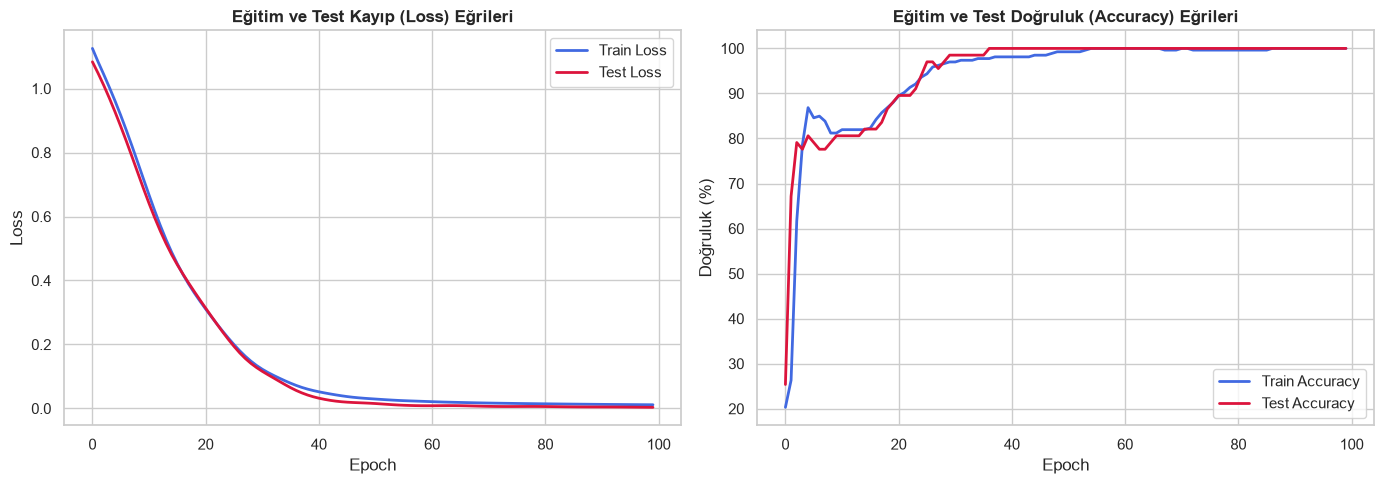

In [17]:
plt.figure(figsize=(14, 5))

# Kayıp (Loss) Grafiği
plt.subplot(1, 2, 1)
plt.plot(epoch_count, train_loss_values, label="Train Loss", color="royalblue", lw=2)
plt.plot(epoch_count, test_loss_values, label="Test Loss", color="crimson", lw=2)
plt.title("Eğitim ve Test Kayıp (Loss) Eğrileri", fontsize=12, weight="bold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 2)
plt.plot(epoch_count, train_acc_values, label="Train Accuracy", color="royalblue", lw=2)
plt.plot(epoch_count, test_acc_values, label="Test Accuracy", color="crimson", lw=2)
plt.title("Eğitim ve Test Doğruluk (Accuracy) Eğrileri", fontsize=12, weight="bold")
plt.xlabel("Epoch")
plt.ylabel("Doğruluk (%)")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Performans Değerlendirmesi: Confusion Matrix (Karmaşıklık Matrisi)

Doğruluk oranının (%100) arkasında sınıfların nasıl ayrıldığını inceleyelim:

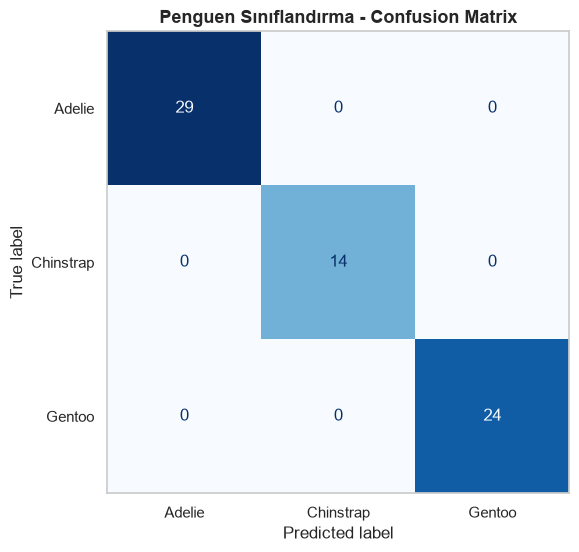

In [18]:
model.eval()
with torch.inference_mode():
    final_test_logits = model(X_test_tensor)
    final_test_preds = final_test_logits.argmax(dim=1)

# Confusion Matrix
cm = confusion_matrix(y_test_tensor.numpy(), final_test_preds.numpy())
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Penguen Sınıflandırma - Confusion Matrix", fontsize=13, weight="bold")
plt.grid(False)
plt.show()

## 11. Modelin Diske Kaydedilmesi (`.pth`) & Canlı Çıkarım (Inference)

Eğitilen modelin `state_dict` sözlüğünü kaydedip diske mühürlüyoruz:

In [19]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "penguin_classifier_model.pth"
MODEL_SAVE_PATH = MODEL_DIR / MODEL_NAME

torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model başarıyla kaydedildi: {MODEL_SAVE_PATH}")

Model başarıyla kaydedildi: models/penguin_classifier_model.pth


### 🔮 Canlı Test: Yeni Bir Penguen Örneği ile Tahmin

In [20]:
# 1. Yeni bir penguen ölçümü: [gaga_boyu=50.0, gaga_derinliği=15.0, yüzgeç=220.0, ağırlık=5000.0]
yeni_penguen = np.array([[50.0, 15.0, 220.0, 5000.0]])

# 2. ÖNEMLİ: Aynı scaler ile normalize ediyoruz!
yeni_penguen_scaled = scaler.transform(yeni_penguen)
yeni_tensor = torch.tensor(yeni_penguen_scaled, dtype=torch.float32)

# 3. Model çıkarımı
model.eval()
with torch.inference_mode():
    logits = model(yeni_tensor)
    probs = torch.softmax(logits, dim=1)[0]
    tahmin_idx = torch.argmax(probs).item()

print(f"Tahmin Edilen Tür: {le.classes_[tahmin_idx]}")
print(f"Güven Oranı (Confidence): %{probs[tahmin_idx].item() * 100:.2f}")
print("\nTüm Olasılık Dağılımı:")
for i, tur in enumerate(le.classes_):
    print(f"  {tur:10s}: %{probs[i].item() * 100:.2f}")

Tahmin Edilen Tür: Gentoo
Güven Oranı (Confidence): %100.00

Tüm Olasılık Dağılımı:
  Adelie    : %0.00
  Chinstrap : %0.00
  Gentoo    : %100.00


## 📝 Modül Özeti & Önemli Çıkarımlar

1. **Ölçeklendirme Hayatidir:** Farklı birimlerdeki özellikler (`body_mass_g` 4500g vs `bill_depth` 17mm) sinir ağlarında gradyan dengesini bozar. `StandardScaler` ile model başarısı **%43'ten %100'e** çıkmıştır.
2. **Data Leakage Engeli:** `scaler.fit_transform()` sadece eğitim kümesine uygulanmış; test kümesine sadece `scaler.transform()` yapılmıştır.
3. **Parametrik Mimari:** `in_features` ve `out_features` değerleri esnek yapılandırılarak üretim standardına uygun bir `nn.Module` yazılmıştır.
4. **Çoklu Sınıflandırma Standartları:** `nn.CrossEntropyLoss` ile ham lojitler eğitilmiş; çıkarım (inference) anında `torch.softmax` ve `torch.argmax` zinciri uygulanmıştır.

---
*Geliştirici: Tunahan Bucak | PyTorch & Deep Learning Mastery*